In [1]:
import os
import warnings

warnings.filterwarnings('ignore')

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Scikit-learn & Modeling
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier


In [2]:
from pathlib import Path

In [3]:
BASE_DIR = Path("..").resolve()
DATA_DIR = BASE_DIR / 'data'
data_path = DATA_DIR / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df_raw = pd.read_csv(data_path)

df_raw.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [30]:
df_raw.shape

(7043, 21)

In [31]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [32]:
df_raw['MonthlyCharges'] = pd.to_numeric(df_raw['MonthlyCharges'], errors='coerce')
df_raw['TotalCharges'] = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')

In [33]:
df_raw= df_raw.replace(r'^\s*$', np.nan, regex=True)

# Now check for nulls again - it will catch them!
print(df_raw.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [34]:
df_raw.dropna(inplace=True)

In [35]:
numerical_columns = ['MonthlyCharges', 'TotalCharges', 'tenure']
df_raw[numerical_columns].describe()

,MonthlyCharges,TotalCharges,tenure
count,7032.000000,7032.000000,7032.000000
mean,64.798208,2283.300441,32.421786
std,30.085974,2266.771362,24.545260
min,18.250000,18.800000,1.000000
25%,35.587500,401.450000,9.000000
50%,70.350000,1397.475000,29.000000
75%,89.862500,3794.737500,55.000000
max,118.750000,8684.800000,72.000000


In [36]:
for col in df_raw.columns:
    print(f"{col}: {df_raw[col].unique()}")

customerID: ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender: ['Female' 'Male']
SeniorCitizen: [0 1]
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
tenure: [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26 39]
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 '

In [37]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

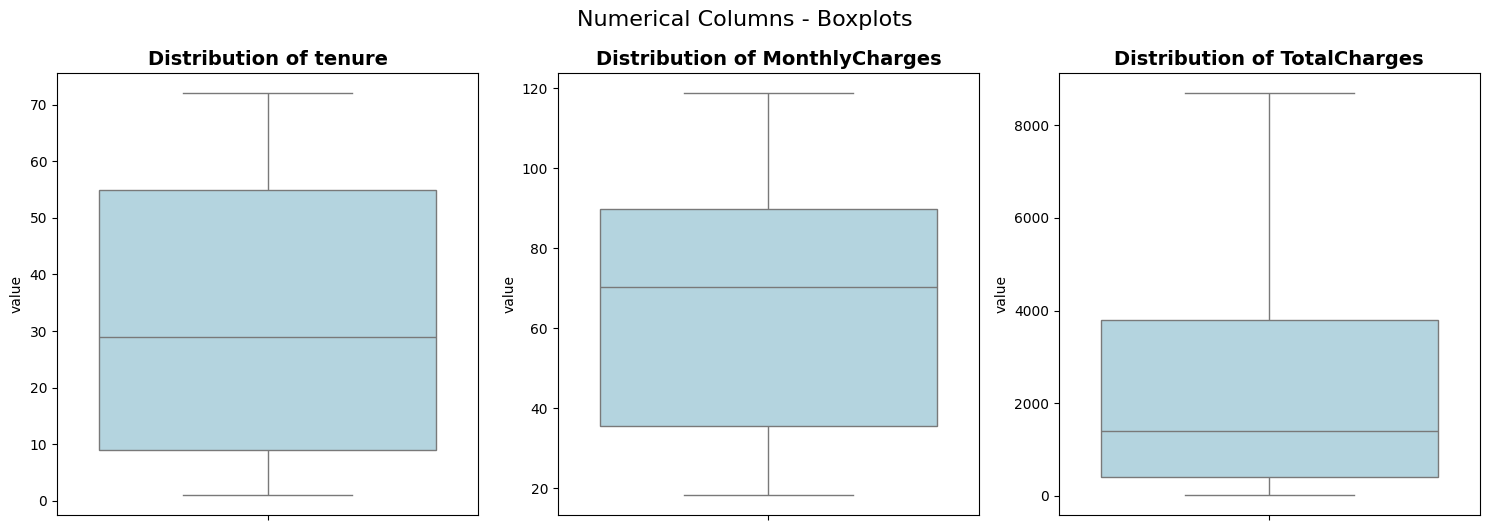

In [38]:
numerical_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(numerical_columns):
    sns.boxplot(data=df_raw, y=col, ax=axes[i], color='lightblue')
    axes[i].set_title(f'Distribution of {col}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('value')

plt.tight_layout()
plt.suptitle('Numerical Columns - Boxplots', fontsize=16, y=1.05) # Add a main title
plt.show()

In [39]:
df_clean = df_raw.copy()
df_clean.to_csv('cleaned_customer_data.csv', index=False)
print(f"Cleaned dataset saved successfully: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns.")


Cleaned dataset saved successfully: 7032 rows, 21 columns.


## Exploratory Data Analysis (EDA)

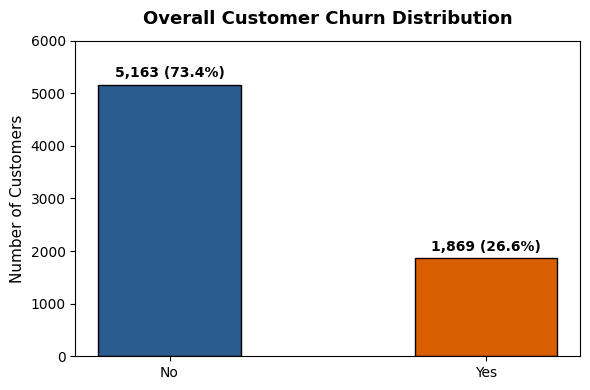

Overall Churn Rate: 26.58% (No: 5,163, Yes: 1,869)


In [40]:
df_clean['Churn_binary'] = (df_clean['Churn'] == 'Yes').astype(int)
overall_churn_pct = df_clean['Churn_binary'].mean() * 100

# Binning for exploratory segmentation
df_clean['Tenure_Group'] = pd.cut(df_clean['tenure'], bins=[-1, 12, 24, 36, 48, 60, 72], 
                                  labels=['0-12 mo', '13-24 mo', '25-36 mo', '37-48 mo', '49-60 mo', '61-72 mo'])
df_clean['MonthlyCharges_Group'] = pd.cut(df_clean['MonthlyCharges'], bins=[0, 30, 60, 90, 120,150], 
                                         labels=['Very Low (<$30)', 'Low ($30-$60)', 'Medium ($60-$90)', 'High (>$90)', 'Very High (>$120)'])

# Visual 1: Churn Distribution
fig, ax = plt.subplots(figsize=(6, 4))
churn_counts = df_clean['Churn'].value_counts()
bars = ax.bar(churn_counts.index, churn_counts.values, color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.45)
ax.set_title('Overall Customer Churn Distribution', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Customers', fontsize=11)
ax.set_ylim(0, 6000)
for b in bars:
    h = b.get_height()
    pct = (h / len(df_clean)) * 100
    ax.text(b.get_x() + b.get_width()/2.0, h + 80, f'{h:,} ({pct:.1f}%)', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Overall Churn Rate: {overall_churn_pct:.2f}% (No: {churn_counts['No']:,}, Yes: {churn_counts['Yes']:,})")


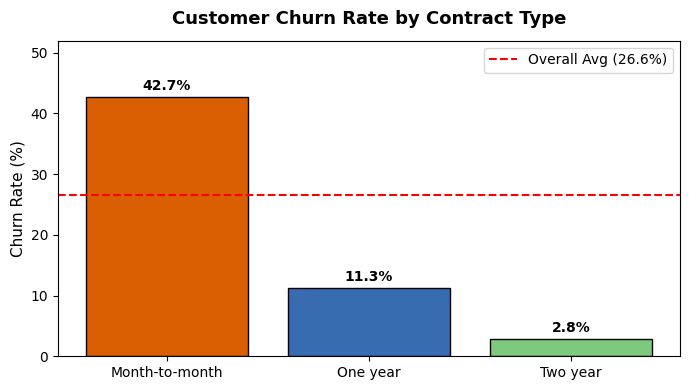

In [41]:
# Visual 2: Churn Rate by Contract Type
fig, ax = plt.subplots(figsize=(7, 4))
contract_cr = df_clean.groupby('Contract')['Churn_binary'].mean() * 100
bars = ax.bar(contract_cr.index, contract_cr.values, color=['#d95f02', '#386cb0', '#7fc97f'], edgecolor='black')
ax.axhline(overall_churn_pct, color='red', linestyle='--', label=f'Overall Avg ({overall_churn_pct:.1f}%)')
ax.set_title('Customer Churn Rate by Contract Type', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Churn Rate (%)', fontsize=11)
ax.set_ylim(0, 52)
for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2.0, h + 1.2, f'{h:.1f}%', ha='center', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


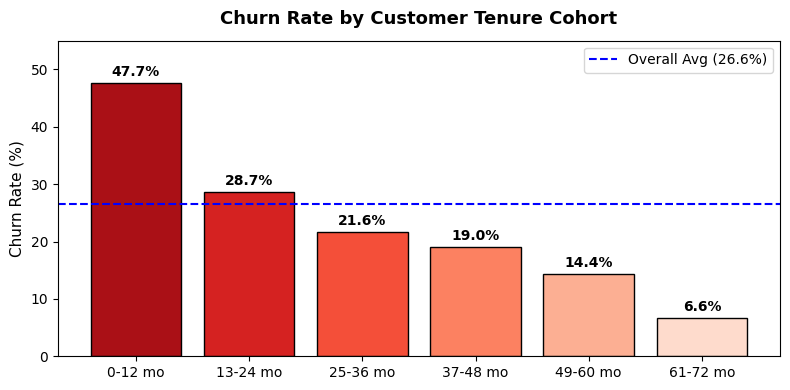

In [42]:
# Visual 3: Churn Rate by Customer Tenure Cohort
fig, ax = plt.subplots(figsize=(8, 4))
tenure_cr = df_clean.groupby('Tenure_Group', observed=False)['Churn_binary'].mean() * 100
bars = ax.bar(tenure_cr.index.astype(str), tenure_cr.values, color=sns.color_palette("Reds_r", len(tenure_cr)), edgecolor='black')
ax.axhline(overall_churn_pct, color='blue', linestyle='--', label=f'Overall Avg ({overall_churn_pct:.1f}%)')
ax.set_title('Churn Rate by Customer Tenure Cohort', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Churn Rate (%)', fontsize=11)
ax.set_ylim(0, 55)
for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2.0, h + 1.2, f'{h:.1f}%', ha='center', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


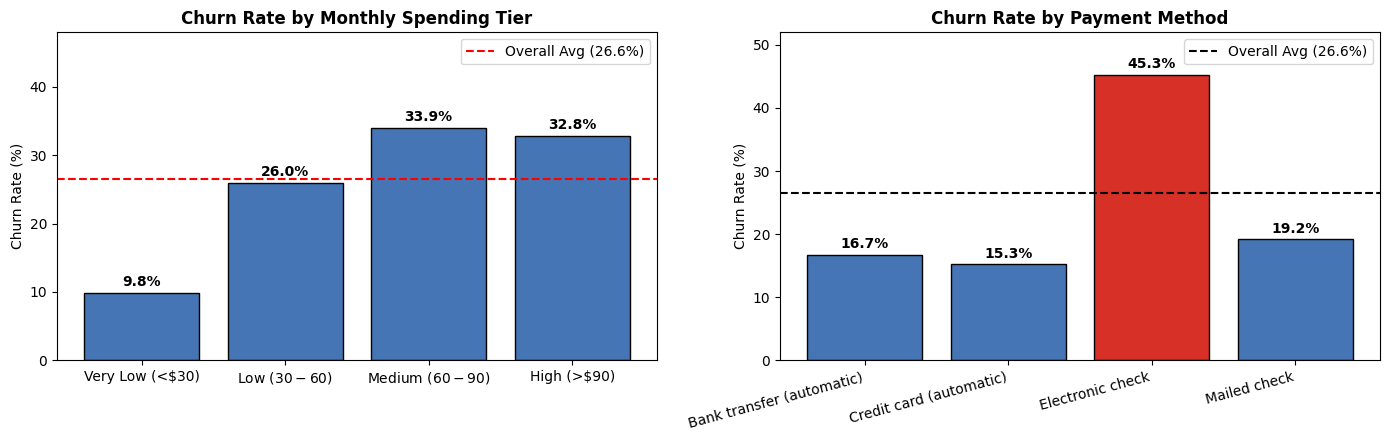

In [43]:
# Visual 4 & 5: Churn Rate by Monthly Spending & Payment Method
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Spending
spend_cr = df_clean.groupby('MonthlyCharges_Group', observed=False)['Churn_binary'].mean() * 100
axes[0].bar(spend_cr.index.astype(str), spend_cr.values, color='#4575b4', edgecolor='black')
axes[0].axhline(overall_churn_pct, color='red', linestyle='--', label=f'Overall Avg ({overall_churn_pct:.1f}%)')
axes[0].set_title('Churn Rate by Monthly Spending Tier', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)', fontsize=10)
axes[0].set_ylim(0, 48)
for i, v in enumerate(spend_cr.values):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0].legend()

# Payment Method
pm_cr = df_clean.groupby('PaymentMethod')['Churn_binary'].mean() * 100
axes[1].bar(pm_cr.index, pm_cr.values, color=['#4575b4', '#4575b4', '#d73027', '#4575b4'], edgecolor='black')
axes[1].axhline(overall_churn_pct, color='black', linestyle='--', label=f'Overall Avg ({overall_churn_pct:.1f}%)')
axes[1].set_title('Churn Rate by Payment Method', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)', fontsize=10)
axes[1].set_xticklabels(pm_cr.index, rotation=15, ha='right')
axes[1].set_ylim(0, 52)
for i, v in enumerate(pm_cr.values):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


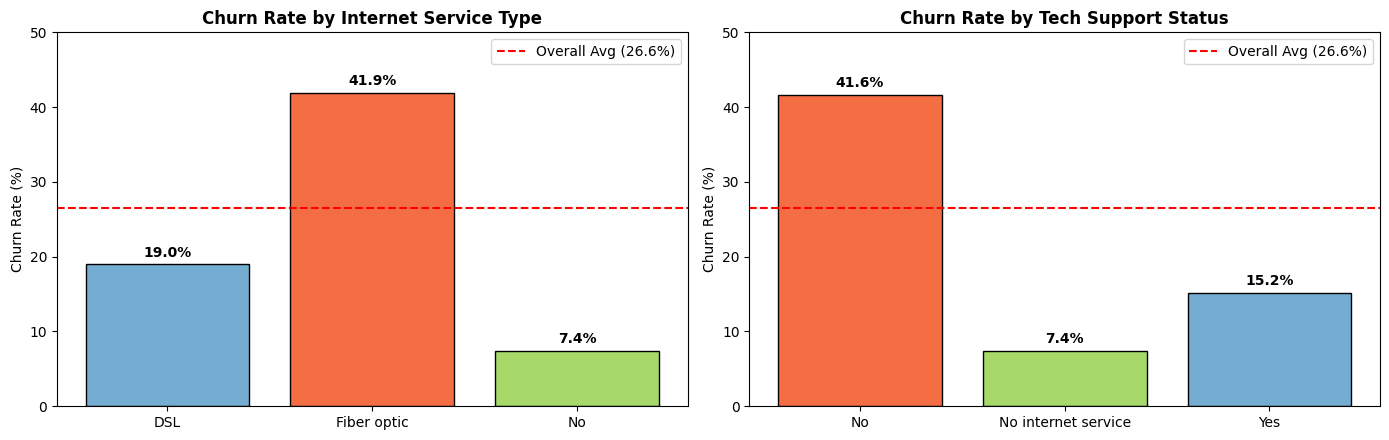

In [44]:
# Visual 6: Internet Service & Tech Support
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

is_cr = df_clean.groupby('InternetService')['Churn_binary'].mean() * 100
axes[0].bar(is_cr.index, is_cr.values, color=['#74add1', '#f46d43', '#a6d96a'], edgecolor='black')
axes[0].axhline(overall_churn_pct, color='red', linestyle='--', label=f'Overall Avg ({overall_churn_pct:.1f}%)')
axes[0].set_title('Churn Rate by Internet Service Type', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)', fontsize=10)
axes[0].set_ylim(0, 50)
for i, v in enumerate(is_cr.values):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0].legend()

ts_cr = df_clean.groupby('TechSupport')['Churn_binary'].mean() * 100
axes[1].bar(ts_cr.index, ts_cr.values, color=['#f46d43', '#a6d96a', '#74add1'], edgecolor='black')
axes[1].axhline(overall_churn_pct, color='red', linestyle='--', label=f'Overall Avg ({overall_churn_pct:.1f}%)')
axes[1].set_title('Churn Rate by Tech Support Status', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)', fontsize=10)
axes[1].set_ylim(0, 50)
for i, v in enumerate(ts_cr.values):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


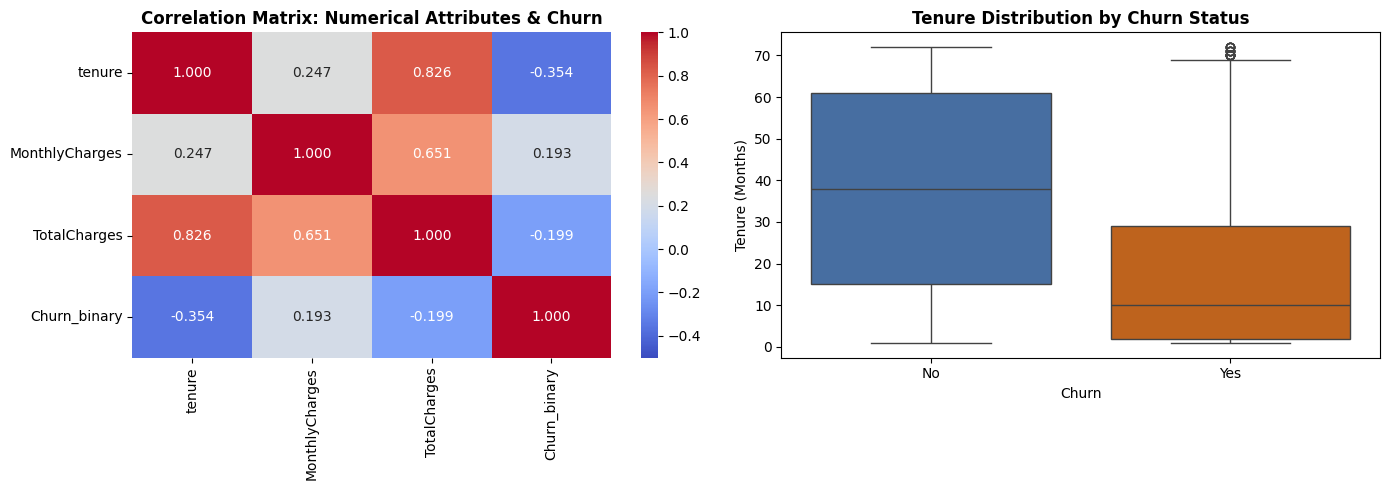

In [45]:
# Visual 7 & 8: Numerical Correlation Heatmap & Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap
corr = df_clean[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_binary']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f', ax=axes[0], cbar=True, vmin=-0.5, vmax=1.0)
axes[0].set_title('Correlation Matrix: Numerical Attributes & Churn', fontsize=12, fontweight='bold')

# Tenure Boxplot
sns.boxplot(x='Churn', y='tenure', data=df_clean, ax=axes[1], palette=['#386cb0', '#d95f02'], hue='Churn', legend=False)
axes[1].set_title('Tenure Distribution by Churn Status', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Tenure (Months)', fontsize=10)

plt.tight_layout()
plt.show()


In [46]:
# Define X and y
target_col = 'Churn_binary'
drop_cols = ['customerID', 'Churn', target_col, 'Tenure_Group', 'MonthlyCharges_Group']
X = df_clean.drop(columns=drop_cols)
y = df_clean[target_col]
customer_ids = df_clean['customerID']

num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

assert not ({'Churn', target_col} & set(X.columns)), 'Target column leaked into X'

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Numerical features ({len(num_features)}): {num_features}")
print(f"Categorical features ({len(cat_features)}): {cat_features}")


Feature matrix X shape: (7032, 19)
Target vector y shape: (7032,)
Numerical features (3): ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features (16): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [47]:
# Train-test split (80/20 Stratified)
X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, customer_ids, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples ({y_train.mean()*100:.2f}% churn)")
print(f"Testing set:  {X_test.shape[0]} samples ({y_test.mean()*100:.2f}% churn)")


Training set: 5625 samples (26.58% churn)
Testing set:  1407 samples (26.58% churn)


## Preprocessing Pipeline

In [48]:
# Define ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

# Fit on training data only
preprocessor.fit(X_train)
cat_encoder = preprocessor.named_transformers_['cat']
encoded_feature_names = num_features + list(cat_encoder.get_feature_names_out(cat_features))
print(f"Total encoded features: {len(encoded_feature_names)}")


Total encoded features: 30


In [49]:
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier


In [50]:
candidate_models = {
    'Logistic Regression (Balanced)': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    'Random Forest (Balanced)': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(class_weight='balanced', n_estimators=150, max_depth=7, min_samples_split=10, random_state=42))
    ]),
    'XGBoost (Balanced)': Pipeline([
        ('prep', preprocessor),
        ('clf', XGBClassifier( n_estimators=100, max_depth=4, learning_rate=0.08, random_state=42, eval_metric='logloss'))
    ]),
    'Logistic Regression (Default)': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest (Default)': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=7, min_samples_split=10, random_state=42))
    ]),
    'SVM': Pipeline([
        ('prep', preprocessor),
        ('clf', SVC(class_weight='balanced', probability=True, random_state=42))
    ]),
    'CatBoost': Pipeline([
        ('prep', preprocessor),
        ('clf', CatBoostClassifier(
            iterations=200,
            depth=5,
            learning_rate=0.05,
            loss_function='Logloss',
            eval_metric='AUC',
            verbose=0,
            random_seed=42
        ))
    ]),
    'KNN': Pipeline([
        ('prep', preprocessor),
        ('clf', KNeighborsClassifier(
            n_neighbors=15,
            weights='distance',
            metric='minkowski'
        ))
    ]),
    'MLP': Pipeline([
        ('prep', preprocessor),
        ('clf', MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation='relu',
            solver='adam',
            alpha=0.0001,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42
        ))
    ])
}


In [51]:
# Fit every candidate pipeline
for pipe in candidate_models.values():
    pipe.fit(X_train, y_train)

# Evaluate all models on the test set
test_results = {}

for name, pipe in candidate_models.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    test_results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

df_test_results = pd.DataFrame(test_results).T

# Rank models:
# 1. F1-Score - primary metric
# 2. ROC-AUC - secondary metric
df_test_results = df_test_results.sort_values(
    by=['F1-Score', 'ROC-AUC'],
    ascending=[False, False]
)

display(df_test_results)

# Select the best model
best_model_name = df_test_results.index[0]
best_model = candidate_models[best_model_name]
best_metrics = df_test_results.loc[best_model_name]

print(f"Best model: {best_model_name}")
print(best_metrics.round(4).to_string())

# Save model
model_dir = 'models'
os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(model_dir, 'best_churn_model.pkl')

joblib.dump(best_model, model_path)

# Save model bundle with metadata
joblib.dump(
    {
        'model': best_model,
        'model_name': best_model_name,
        'metrics': best_metrics.to_dict(),
        'numeric_features': num_features,
        'categorical_features': cat_features,
        'trained_at': pd.Timestamp.now().isoformat()
    },
    os.path.join(model_dir, 'best_churn_model_bundle.pkl')
)

# Verify saved model
reloaded = joblib.load(model_path)

print(
    f"Saved: {model_path} "
    f"({os.path.getsize(model_path)/1024:.1f} KB)"
)

print(
    f"Reload check accuracy: "
    f"{accuracy_score(y_test, reloaded.predict(X_test)):.4f}"
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest (Balanced),0.732765,0.498361,0.812834,0.617886,0.839326
Logistic Regression (Default),0.804549,0.650456,0.572193,0.608819,0.836071
Logistic Regression (Balanced),0.725657,0.490099,0.794118,0.606122,0.835344
SVM,0.727079,0.491611,0.783422,0.604124,0.810069
MLP,0.800284,0.642202,0.561497,0.599144,0.836615
CatBoost,0.802416,0.657895,0.534759,0.589971,0.840507
XGBoost (Balanced),0.796731,0.638365,0.542781,0.586705,0.839444
KNN,0.765458,0.560440,0.545455,0.552846,0.800717
Random Forest (Default),0.787491,0.637363,0.465241,0.537867,0.839353


Best model: Random Forest (Balanced)
Accuracy     0.7328
Precision    0.4984
Recall       0.8128
F1-Score     0.6179
ROC-AUC      0.8393
Saved: models\best_churn_model.pkl (2163.1 KB)
Reload check accuracy: 0.7328
